# Customer Churn Prediction: Online Retail II

**Project title:** Analysis and Prediction Using Machine Learning Techniques
**Author:** Fathimathul Amana 
**Date:** 02-11-2026

---

## 1. Introduction

**Problem statement:** Using each customer's purchase history up to **10 September 2011**, predict whether the customer will
**stop buying (churn)** during the following ~90 days (10 September to 9 December 2011).

**Why it matters:** A retailer cannot contact every customer. If it can tell in advance which customers are likely to
stop buying, it can focus win-back offers on them instead of spending on customers who would have bought anyway.

**Dataset overview**
- **Source:** Online Retail II, UCI Machine Learning Repository (UK-based online gift retailer, Dec 2009 to Dec 2011).
- **Input to this notebook:** the cleaned sales table produced in `online_retail_analysis.ipynb`
  (cancellations, non-product codes, zero-price rows and three data-entry errors already removed).
- **Unit of analysis:** one row per customer (about 5,256 customers who bought before the cutoff date).

**Contents**
1. Introduction
2. Building the churn dataset
3. Data Understanding
4. Exploratory Data Analysis
5. Data Preprocessing
6. Hyperparameter Tuning and Cross-Validation (concepts)
7. Model Building
8. Model Evaluation
9. Conclusion
10. References

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay)
from sklearn.utils import resample
from xgboost import XGBClassifier
HAS_XGB = True

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
os.makedirs("../images", exist_ok=True)
RANDOM_STATE = 42

## 2. Building the Churn Dataset

**Idea:** to predict the future honestly, the model may only see the **past**.

- **Cutoff date:** 10 September 2011
- **Features:** calculated only from purchases **before** the cutoff
- **Label (`Churn`):** `1` if the customer made **no purchase** after the cutoff, `0` if they bought again

Using information from after the cutoff to build features would be **data leakage**, which makes results look
better than they really are.

| Feature | Meaning |
|---|---|
| Recency | Days between the customer's last purchase and the cutoff |
| Tenure | Days between the customer's first purchase and the cutoff |
| Frequency | Number of different orders (invoices) |
| Monetary | Total money spent |
| TotalItems | Total number of items bought |
| UniqueProducts | Number of different products bought |
| AvgOrderValue | Monetary / Frequency |
| Country | Customer's country |

In [2]:
df = pd.read_csv("../data/processed/sales_customers.csv", parse_dates=["InvoiceDate"])
print("Rows loaded:", df.shape)
print("Customers:", df["Customer ID"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Rows loaded: (776575, 17)
Customers: 5852
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [3]:
cutoff = pd.Timestamp("2011-09-10")

history = df[df["InvoiceDate"] < cutoff]       # what the model is allowed to see
future = df[df["InvoiceDate"] >= cutoff]       # used ONLY to create the label

customers = history.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (cutoff - x.max()).days),
    Tenure=("InvoiceDate", lambda x: (cutoff - x.min()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
    TotalItems=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    Country=("Country", "first"),
)
customers["AvgOrderValue"] = customers["Monetary"] / customers["Frequency"]

bought_again = future["Customer ID"].unique()
customers["Churn"] = (~customers.index.isin(bought_again)).astype(int)

print(customers.shape)
customers["Churn"].value_counts()

(5256, 9)


Churn
1    2968
0    2288
Name: count, dtype: int64

## 3. Data Understanding

In [4]:
print("Shape:", customers.shape)
print("Size:", customers.size)
print("Columns:", list(customers.columns))
print()
print("Data types:")
print(customers.dtypes)
print()
print("Unique values per column:")
print(customers.nunique())
print()
print("Churn value counts:")
print(customers["Churn"].value_counts())
print()
print("Country value counts (top 5):")
print(customers["Country"].value_counts().head(5))

Shape: (5256, 9)
Size: 47304
Columns: ['Recency', 'Tenure', 'Frequency', 'Monetary', 'TotalItems', 'UniqueProducts', 'Country', 'AvgOrderValue', 'Churn']

Data types:
Recency             int64
Tenure              int64
Frequency           int64
Monetary          float64
TotalItems          int64
UniqueProducts      int64
Country               str
AvgOrderValue     float64
Churn               int64
dtype: object

Unique values per column:
Recency            515
Tenure             519
Frequency           81
Monetary          5151
TotalItems        2143
UniqueProducts     412
Country             41
AvgOrderValue     5153
Churn                2
dtype: int64

Churn value counts:
Churn
1    2968
0    2288
Name: count, dtype: int64

Country value counts (top 5):
Country
United Kingdom    4799
Germany             93
France              74
Spain               31
Belgium             26
Name: count, dtype: int64


In [5]:
customers.head()

,Recency,Tenure,Frequency,Monetary,TotalItems,UniqueProducts,Country,AvgOrderValue,Churn
Customer ID,,,,,,,,,
12346,438,556,2,169.36,24,24,United Kingdom,84.680,1
12347,38,313,6,3402.39,2099,107,Iceland,567.065,0
12348,157,347,4,1388.40,2488,24,Finland,347.100,0
12349,316,498,2,2221.14,991,89,Italy,1110.570,0
12350,219,219,1,294.40,196,16,Norway,294.400,1


In [6]:
customers.tail()

,Recency,Tenure,Frequency,Monetary,TotalItems,UniqueProducts,Country,AvgOrderValue,Churn
Customer ID,,,,,,,,,
18283,4,567,16,1700.25,1039,284,United Kingdom,106.265625,0
18284,340,340,1,411.68,493,27,United Kingdom,411.680000,1
18285,569,569,1,377.00,144,11,United Kingdom,377.000000,1
18286,385,632,2,1246.43,607,66,United Kingdom,623.215000,1
18287,110,480,5,3060.99,1914,92,United Kingdom,612.198000,0


In [7]:
customers.info()

<class 'pandas.DataFrame'>
Index: 5256 entries, 12346 to 18287
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Recency         5256 non-null   int64  
 1   Tenure          5256 non-null   int64  
 2   Frequency       5256 non-null   int64  
 3   Monetary        5256 non-null   float64
 4   TotalItems      5256 non-null   int64  
 5   UniqueProducts  5256 non-null   int64  
 6   Country         5256 non-null   str    
 7   AvgOrderValue   5256 non-null   float64
 8   Churn           5256 non-null   int64  
dtypes: float64(2), int64(6), str(1)
memory usage: 410.6 KB


In [8]:
customers.describe().round(2)

,Recency,Tenure,Frequency,Monetary,TotalItems,UniqueProducts,AvgOrderValue,Churn
count,5256.00,5256.00,5256.00,5256.00,5256.00,5256.00,5256.00,5256.00
mean,205.93,430.67,5.71,2582.58,1613.46,74.55,362.55,0.56
std,174.40,180.69,11.21,12040.44,8001.22,104.98,502.43,0.50
min,0.00,0.00,1.00,1.55,1.00,1.00,1.55,0.00
25%,49.00,310.00,1.00,316.46,169.75,18.00,173.85,0.00
50%,163.00,473.00,3.00,775.74,442.00,41.00,275.02,1.00
75%,324.00,586.00,6.00,2060.92,1204.75,92.00,406.99,1.00
max,647.00,647.00,284.00,456780.49,297934.00,2178.00,14844.77,1.00


In [9]:
customers.corr(numeric_only=True).round(2)

,Recency,Tenure,Frequency,Monetary,TotalItems,UniqueProducts,AvgOrderValue,Churn
Recency,1.00,0.24,-0.30,-0.15,-0.13,-0.33,-0.05,0.43
Tenure,0.24,1.00,0.29,0.14,0.14,0.30,0.02,-0.05
Frequency,-0.30,0.29,1.00,0.63,0.55,0.69,0.09,-0.27
Monetary,-0.15,0.14,0.63,1.00,0.85,0.42,0.32,-0.14
TotalItems,-0.13,0.14,0.55,0.85,1.00,0.38,0.40,-0.12
UniqueProducts,-0.33,0.30,0.69,0.42,0.38,1.00,0.15,-0.31
AvgOrderValue,-0.05,0.02,0.09,0.32,0.40,0.15,1.00,-0.06
Churn,0.43,-0.05,-0.27,-0.14,-0.12,-0.31,-0.06,1.00


**Observations:**
- The table has one row per customer, with 5,256 customers and 9 columns.
- `Churn` is fairly balanced: about 56.5% churned and 43.5% did not.
- The mean of `Monetary` (£2,583) is far above its median (£776), so a few very large customers pull the average up (right-skewed data).

## 4. Exploratory Data Analysis

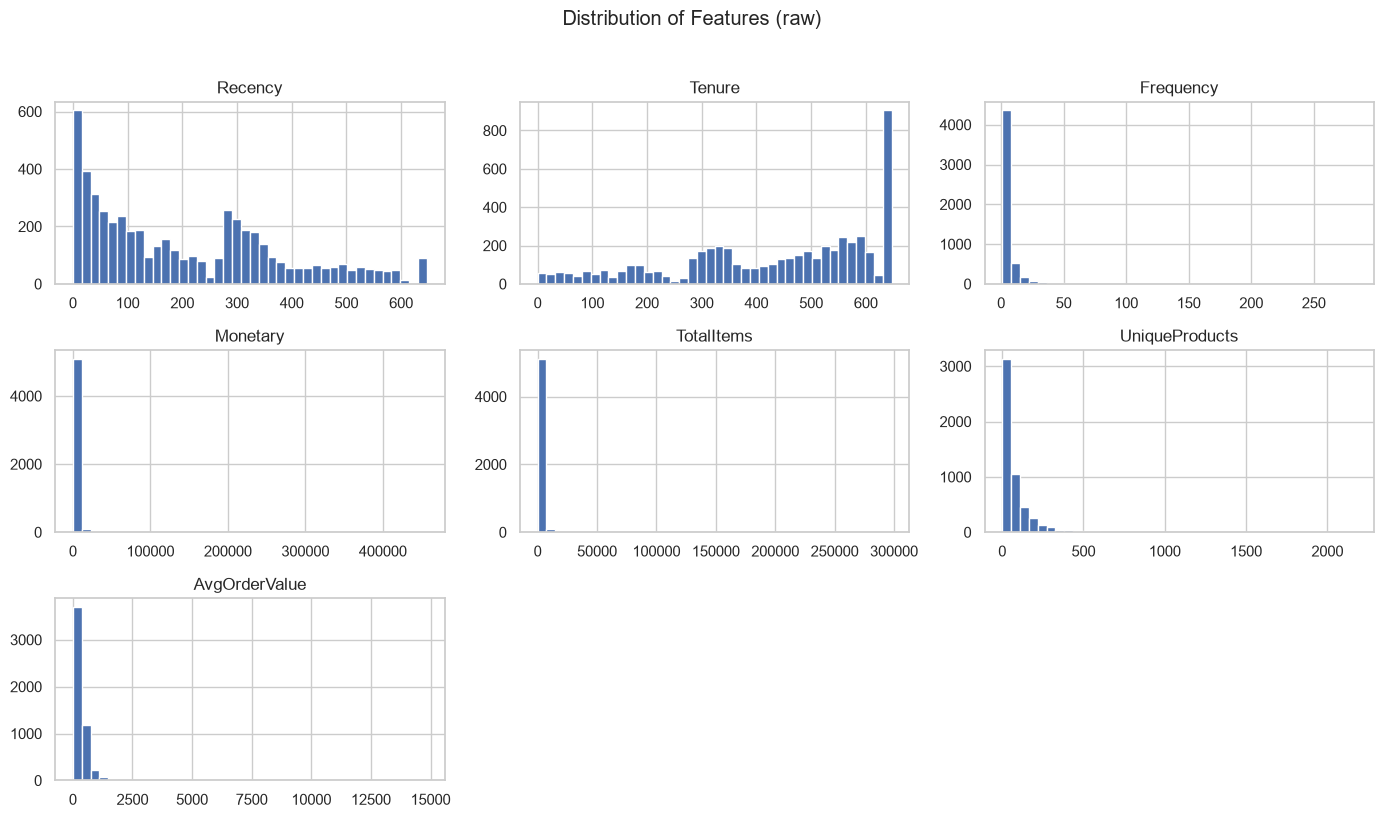

In [10]:
num_cols = ["Recency", "Tenure", "Frequency", "Monetary", "TotalItems", "UniqueProducts", "AvgOrderValue"]

customers[num_cols].hist(bins=40, figsize=(14, 8))
plt.suptitle("Distribution of Features (raw)", y=1.02)
plt.tight_layout()
plt.savefig("../images/ml_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** `Frequency`, `Monetary`, `TotalItems`, and `AvgOrderValue` are heavily right-skewed: most customers are small
and a few are very large. This is handled in preprocessing with a log transform.

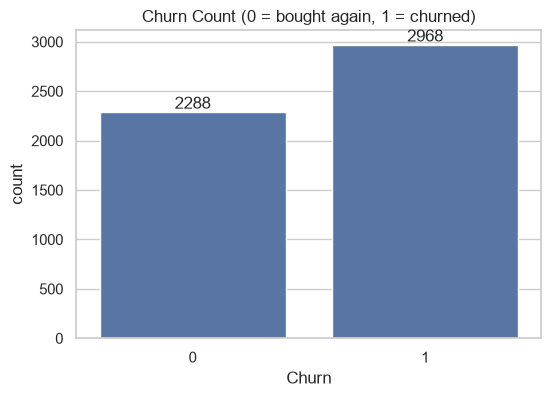

In [11]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Churn", data=customers)
ax.set_title("Churn Count (0 = bought again, 1 = churned)")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.savefig("../images/ml_churn_count.png", dpi=150, bbox_inches="tight")
plt.show()

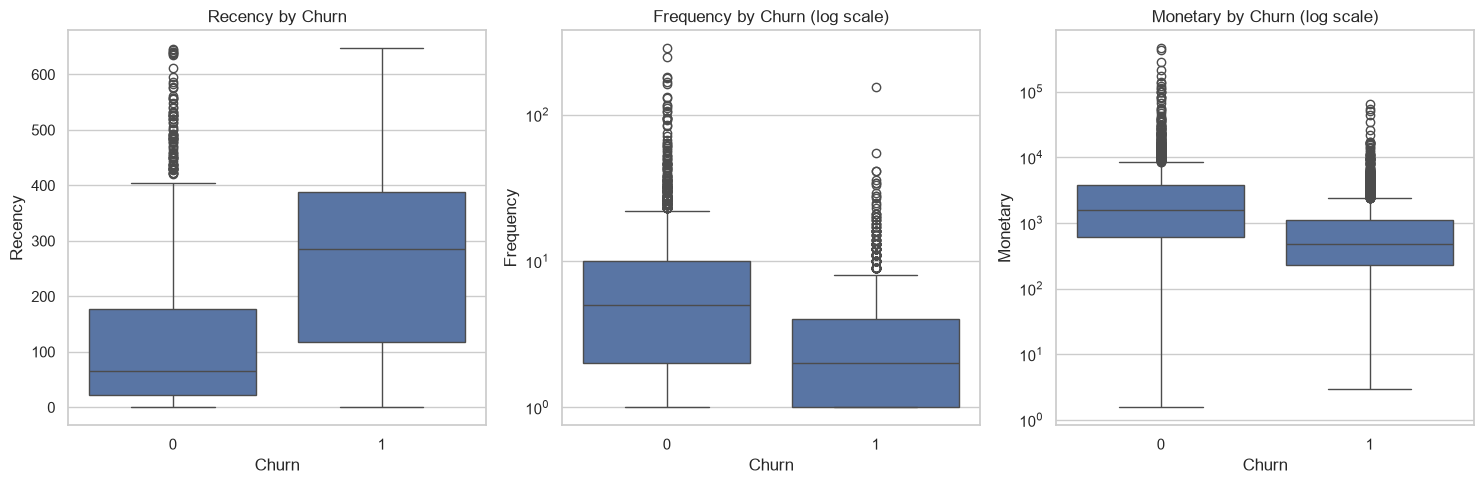

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(x="Churn", y="Recency", data=customers, ax=axes[0])
axes[0].set_title("Recency by Churn")

sns.boxplot(x="Churn", y="Frequency", data=customers, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Frequency by Churn (log scale)")

sns.boxplot(x="Churn", y="Monetary", data=customers, ax=axes[2])
axes[2].set_yscale("log")
axes[2].set_title("Monetary by Churn (log scale)")

plt.tight_layout()
plt.savefig("../images/ml_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** customers who churned tend to have a higher recency (they were already inactive),
and lower frequency and monetary value than customers who bought again.

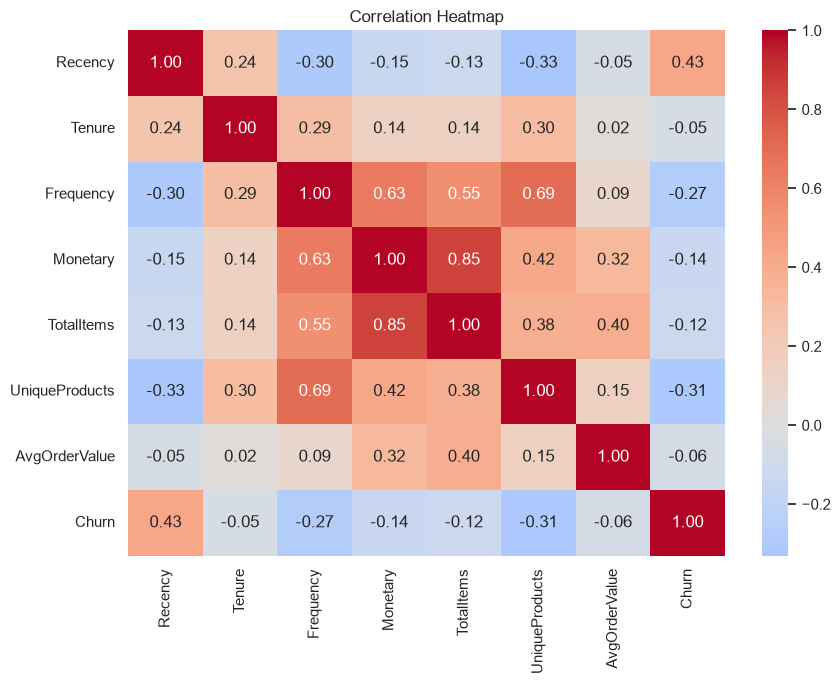

In [13]:
corr = customers[num_cols + ["Churn"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("../images/ml_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight (complete using the chart):** `Recency` has the strongest positive relationship with `Churn`, while `Frequency`,
`Monetary`, and `UniqueProducts` are negatively related to it. Several size-related features (`Monetary`, `TotalItems`,
`Frequency`) are correlated with each other.

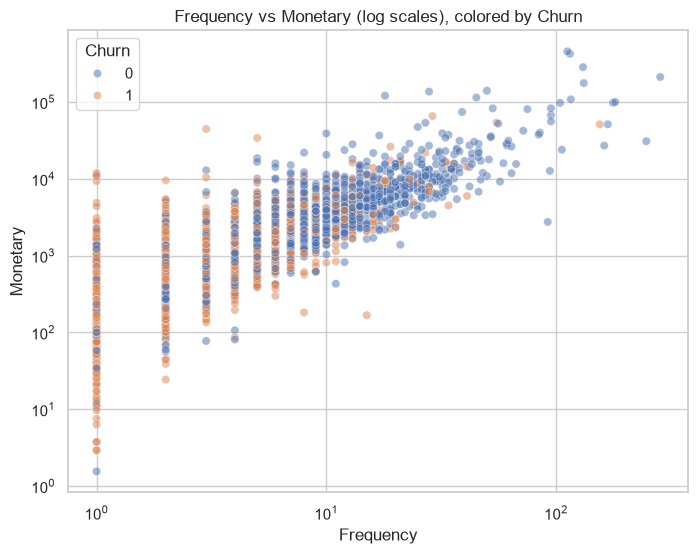

In [14]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=customers, x="Frequency", y="Monetary", hue="Churn", alpha=0.5)
plt.xscale("log")
plt.yscale("log")
plt.title("Frequency vs Monetary (log scales), colored by Churn")
plt.savefig("../images/ml_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

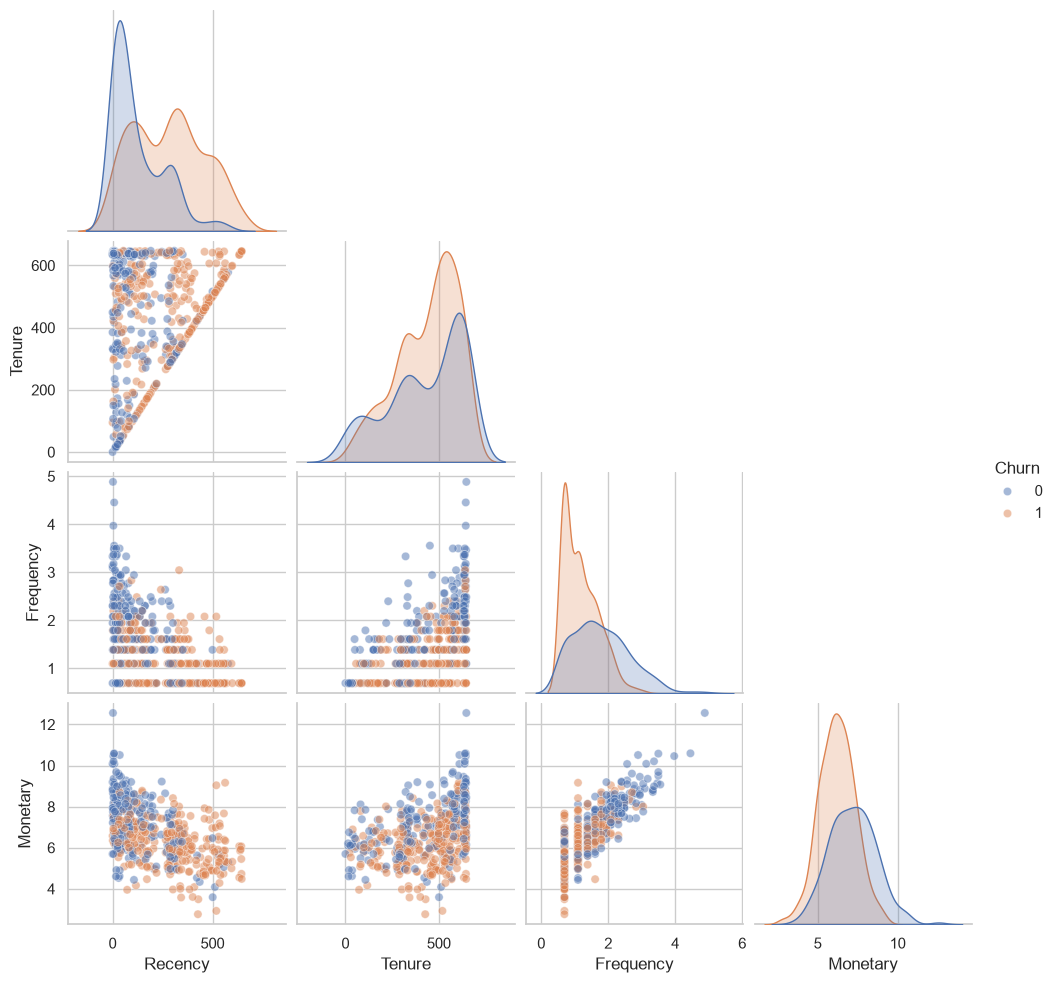

In [15]:
sample = customers[["Recency", "Tenure", "Frequency", "Monetary", "Churn"]].sample(500, random_state=RANDOM_STATE).copy()
sample["Frequency"] = np.log1p(sample["Frequency"])
sample["Monetary"] = np.log1p(sample["Monetary"])

sns.pairplot(sample, hue="Churn", corner=True, plot_kws={"alpha": 0.5})
plt.savefig("../images/ml_pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

*The pair plot uses a random sample of 500 customers and log-transformed `Frequency` and `Monetary`, because it is slow
and unreadable with all customers and heavily skewed values.*

## 5. Data Preprocessing

Steps: missing values, outliers/skewness, encoding categorical variables, train/test split, class balance, scaling.

In [16]:
print("Missing values per column:")
print(customers.isnull().sum())

Missing values per column:
Recency           0
Tenure            0
Frequency         0
Monetary          0
TotalItems        0
UniqueProducts    0
Country           0
AvgOrderValue     0
Churn             0
dtype: int64


**Missing values:** none in the customer table. (Rows without a Customer ID were already excluded in the first notebook,
because a customer-level model needs to know who the customer is.)

In [17]:
skewed = ["Frequency", "Monetary", "TotalItems", "UniqueProducts", "AvgOrderValue"]

print("Skewness BEFORE log transform:")
print(customers[skewed].skew().round(2))

for col in skewed:
    customers[col + "_log"] = np.log1p(customers[col])

print()
print("Skewness AFTER log transform:")
print(customers[[c + "_log" for c in skewed]].skew().round(2))

Skewness BEFORE log transform:
Frequency         10.49
Monetary          24.27
TotalItems        20.88
UniqueProducts     6.12
AvgOrderValue     13.91
dtype: float64

Skewness AFTER log transform:
Frequency_log         1.06
Monetary_log          0.27
TotalItems_log        0.05
UniqueProducts_log   -0.25
AvgOrderValue_log    -0.11
dtype: float64


**Outliers:** the biggest customers (very high `Monetary` or `Frequency`) are real wholesale buyers, not errors.
Deleting them would remove the most valuable customers from the model. Instead, the log transform (`log1p`) shrinks their
influence while keeping every customer. The truly erroneous orders were already removed in the first notebook.

In [18]:
top_countries = ["United Kingdom", "Germany", "France"]
customers["Country_Group"] = np.where(customers["Country"].isin(top_countries), customers["Country"], "Other")

country_dummies = pd.get_dummies(customers["Country_Group"], prefix="Country", dtype=int).drop(columns="Country_Other")
print(customers["Country_Group"].value_counts())
country_dummies.head()

Country_Group
United Kingdom    4799
Other              290
Germany             93
France              74
Name: count, dtype: int64


,Country_France,Country_Germany,Country_United Kingdom
Customer ID,,,
12346,0,0,1
12347,0,0,0
12348,0,0,0
12349,0,0,0
12350,0,0,0


**Encoding:** `Country` is the only categorical feature. It has many values and most customers are in the UK, so every country
except the UK, Germany, and France is grouped into `Other`. The result is one-hot encoded, and the `Other` column is dropped
because it is redundant (a customer with 0 in all three columns is in `Other`, so `Other` acts as the reference group).

In [19]:
feature_cols = ["Recency", "Tenure"] + [c + "_log" for c in skewed]

X = pd.concat([customers[feature_cols], country_dummies], axis=1)
y = customers["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Features:", list(X.columns))
print("Train:", X_train.shape, " Test:", X_test.shape)
print()
print("Churn share in train:", y_train.mean().round(3), " in test:", y_test.mean().round(3))

Features: ['Recency', 'Tenure', 'Frequency_log', 'Monetary_log', 'TotalItems_log', 'UniqueProducts_log', 'AvgOrderValue_log', 'Country_France', 'Country_Germany', 'Country_United Kingdom']
Train: (4204, 10)  Test: (1052, 10)

Churn share in train: 0.565  in test: 0.565


**Train/test split:** 80% of customers train the models, and 20% are kept unseen for the final evaluation.
`stratify=y` keeps the churn share the same in both parts.

**Class balance:** about 56% churned and 44% did not, which is only mildly imbalanced. Oversampling or undersampling is
therefore not needed. (A small experiment at the end of the model building section checks this.)

**Scaling:** `StandardScaler` is applied **inside pipelines** for Logistic Regression and KNN, which are sensitive to the
scale of features. Tree-based models do not need scaling. Doing it inside a pipeline means the scaler is fitted only on
training data in every cross-validation fold, which avoids leakage.

## 6. Hyperparameter Tuning and Cross-Validation

**Hyperparameters** are settings chosen *before* training (for example, how deep a tree may grow, or how many neighbours
KNN uses). They are not learned from the data, and poor choices cause underfitting or overfitting.

**Cross-validation (CV):** the training data is split into 5 parts. The model is trained on 4 parts and tested on the
5th, five times, so every part is used for testing once. The average score is more reliable than a single split. We use
**stratified** 5-fold CV so each fold keeps the churn proportion.

**GridSearchCV** tries every combination from a grid of hyperparameter values, scores each with cross-validation,
and returns the best combination. The test set is never used during tuning.

## 7. Model Building

**Models chosen (classification):**
- **Baseline:** always predicts the most common class. Any useful model must beat it.
- **Logistic Regression:** a linear model that outputs a probability of churn. Simple and easy to explain.
- **K-Nearest Neighbors (KNN):** predicts from the majority class among the K most similar customers.
- **Decision Tree:** a series of if/else questions on the features.
- **Random Forest:** many decision trees trained on random subsets, voting together.
- **AdaBoost / Gradient Boosting / XGBoost:** trees built one after another, each correcting the previous one's mistakes.

In [20]:
models = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=1000))]),
    "KNN": Pipeline([("scaler", StandardScaler()),
                     ("model", KNeighborsClassifier(n_neighbors=15))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
if HAS_XGB:
    models["XGBoost"] = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                                      eval_metric="logloss", random_state=RANDOM_STATE)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
    rows.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
    })

cv_results = pd.DataFrame(rows).set_index("Model").sort_values("CV ROC-AUC", ascending=False).round(3)
cv_results

,CV Accuracy,CV F1,CV ROC-AUC
Model,,,
XGBoost,0.735,0.776,0.804
Gradient Boosting,0.735,0.775,0.803
Logistic Regression,0.734,0.772,0.800
Random Forest,0.727,0.766,0.798
AdaBoost,0.721,0.763,0.791
Decision Tree,0.724,0.760,0.790
KNN,0.715,0.755,0.785
Baseline (majority class),0.565,0.722,0.500


**Reading the table:** the baseline's accuracy equals the churn share (about 0.56) and its ROC-AUC is 0.5 (pure guessing).
Every real model should beat both. ROC-AUC measures how well a model *ranks* churners above non-churners, regardless of the
decision threshold.

In [21]:
param_grids = {
    "Logistic Regression": (
        Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]),
        {"model__C": [0.01, 0.1, 1, 10]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [100, 200], "max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 5, 10]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [100, 200], "learning_rate": [0.03, 0.1], "max_depth": [2, 3]},
    ),
}

best_models = {}
for name, (estimator, grid) in param_grids.items():
    search = GridSearchCV(estimator, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    print(f"{name}\n  best params: {search.best_params_}\n  best CV ROC-AUC: {search.best_score_:.3f}\n")

Logistic Regression
  best params: {'model__C': 0.1}
  best CV ROC-AUC: 0.800

Random Forest
  best params: {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 200}
  best CV ROC-AUC: 0.807

Gradient Boosting
  best params: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}
  best CV ROC-AUC: 0.805



**Tuning summary:** GridSearchCV was run for three models (Logistic Regression, Random Forest, Gradient Boosting).
The best parameters are printed above. Tuning usually improves the cross-validated score only slightly, which is normal
when the features carry limited signal.

In [22]:
# Does balancing the classes help? (oversample the minority class in the TRAINING data only)
train_df = X_train.copy()
train_df["Churn"] = y_train
majority = train_df[train_df["Churn"] == 1]
minority = train_df[train_df["Churn"] == 0]
minority_up = resample(minority, replace=True, n_samples=len(majority), random_state=RANDOM_STATE)
balanced = pd.concat([majority, minority_up])

lr_plain = models["Logistic Regression"].fit(X_train, y_train)
lr_over = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]) \
    .fit(balanced.drop(columns="Churn"), balanced["Churn"])

for label, m in [("Without oversampling", lr_plain), ("With oversampling", lr_over)]:
    pred = m.predict(X_test)
    print(f"{label:22} accuracy={accuracy_score(y_test, pred):.3f}  recall={recall_score(y_test, pred):.3f}  F1={f1_score(y_test, pred):.3f}")

Without oversampling   accuracy=0.733  recall=0.786  F1=0.769
With oversampling      accuracy=0.714  recall=0.694  F1=0.732


**Conclusion of the experiment:** oversampling did not improve the model. Accuracy and F1 were equal or lower than without it
(in our run: accuracy 0.733 to 0.714 and F1 0.769 to 0.732). This confirms that the mild class imbalance does not need
resampling, so the main models are trained on the original data. (Your numbers may differ slightly.)

## 8. Model Evaluation

**Metrics**
- **Accuracy:** share of customers classified correctly.
- **Precision:** of the customers predicted to churn, how many really did.
- **Recall:** of the customers who really churned, how many the model found.
- **F1-score:** balance of precision and recall.
- **ROC-AUC:** ability to rank churners above non-churners (0.5 = guessing, 1.0 = perfect).
- **Confusion matrix:** counts of correct and incorrect predictions for each class.

All numbers below are measured on the **unseen test set**.

In [23]:
final_models = {
    "Baseline (majority class)": models["Baseline (majority class)"],
    "Logistic Regression (tuned)": best_models["Logistic Regression"],
    "KNN": models["KNN"],
    "Decision Tree": models["Decision Tree"],
    "Random Forest (tuned)": best_models["Random Forest"],
    "AdaBoost": models["AdaBoost"],
    "Gradient Boosting (tuned)": best_models["Gradient Boosting"],
}
if HAS_XGB:
    final_models["XGBoost"] = models["XGBoost"]

rows = []
for name, model in final_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False).round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest (tuned),0.730,0.740,0.805,0.771,0.789
XGBoost,0.730,0.749,0.785,0.766,0.788
Gradient Boosting (tuned),0.731,0.747,0.791,0.769,0.788
Logistic Regression (tuned),0.733,0.754,0.783,0.768,0.788
AdaBoost,0.720,0.744,0.768,0.756,0.779
KNN,0.714,0.737,0.768,0.752,0.773
Decision Tree,0.710,0.736,0.758,0.747,0.758
Baseline (majority class),0.565,0.565,1.000,0.722,0.500


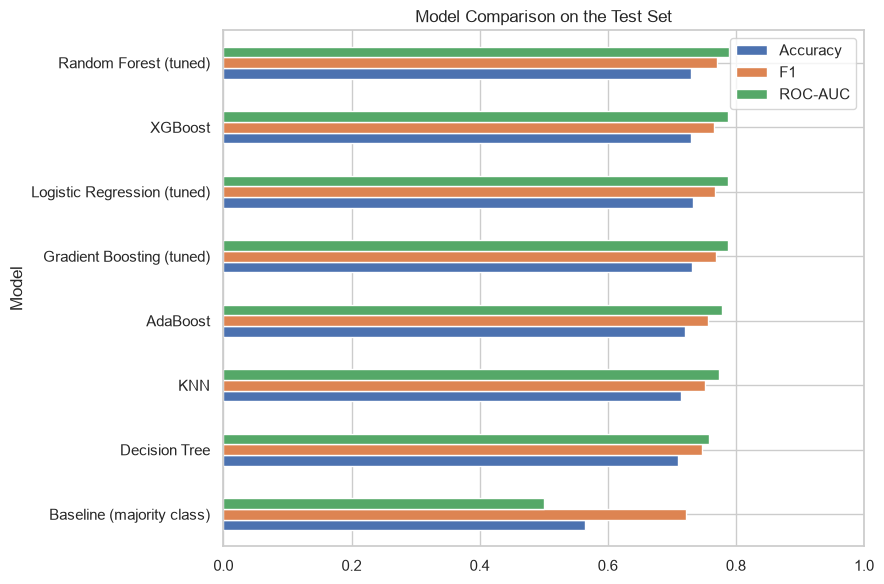

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))
results[["Accuracy", "F1", "ROC-AUC"]].sort_values("ROC-AUC").plot(kind="barh", ax=ax)
ax.set_title("Model Comparison on the Test Set")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.savefig("../images/ml_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Best model by ROC-AUC: Random Forest (tuned)


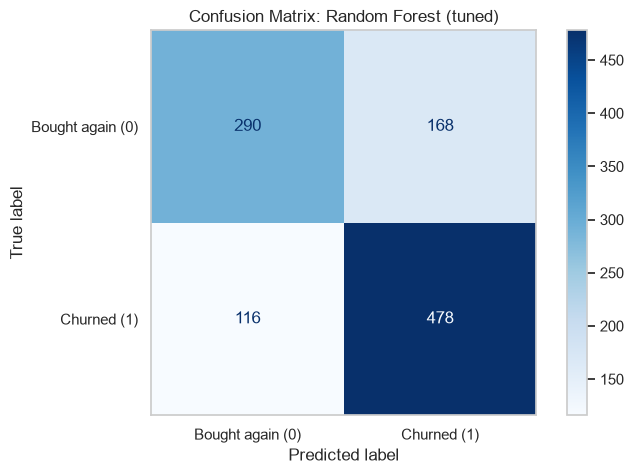

              precision    recall  f1-score   support

Bought again       0.71      0.63      0.67       458
     Churned       0.74      0.80      0.77       594

    accuracy                           0.73      1052
   macro avg       0.73      0.72      0.72      1052
weighted avg       0.73      0.73      0.73      1052



In [25]:
best_name = results["ROC-AUC"].idxmax()
best_model = final_models[best_name]
print("Best model by ROC-AUC:", best_name)

pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, pred)

ConfusionMatrixDisplay(cm, display_labels=["Bought again (0)", "Churned (1)"]).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix: {best_name}")
plt.grid(False)
plt.savefig("../images/ml_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(y_test, pred, target_names=["Bought again", "Churned"]))

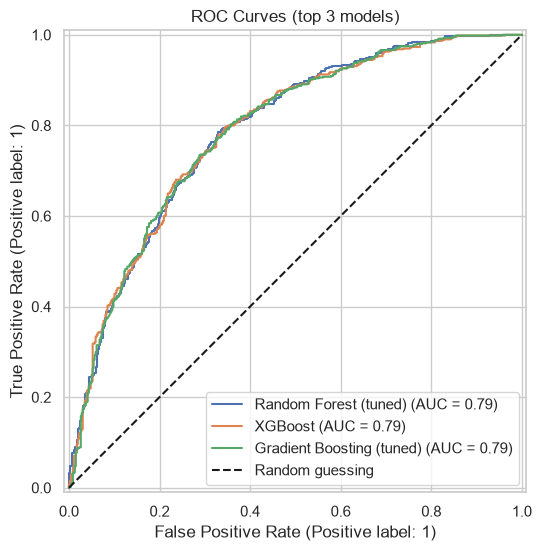

In [26]:
fig, ax = plt.subplots(figsize=(7, 6))
for name in results.drop(index="Baseline (majority class)").index[:3]:
    RocCurveDisplay.from_estimator(final_models[name], X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guessing")
ax.set_title("ROC Curves (top 3 models)")
ax.legend()
plt.savefig("../images/ml_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

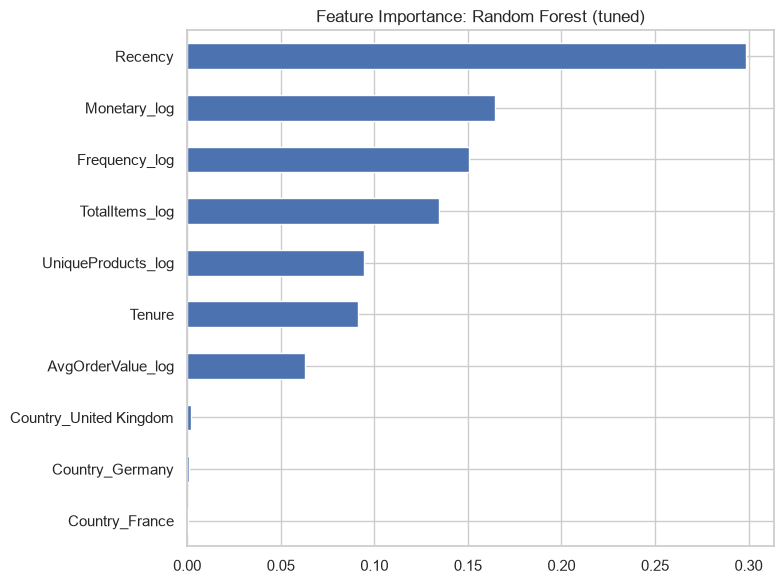

In [27]:
est = final_models[best_name]
if hasattr(est, "feature_importances_"):
    importance = pd.Series(est.feature_importances_, index=X.columns)
    title = "Feature Importance"
elif hasattr(est, "named_steps") and hasattr(est.named_steps["model"], "coef_"):
    importance = pd.Series(est.named_steps["model"].coef_[0], index=X.columns)
    title = "Coefficients (standardized features; positive = more likely to churn)"
else:
    importance = None

if importance is not None:
    fig, ax = plt.subplots(figsize=(8, 6))
    importance.sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"{title}: {best_name}")
    plt.tight_layout()
    plt.savefig("../images/ml_feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()

**Interpretation:**
- The best model by ROC-AUC is Random Forest (tuned) with test accuracy 0.730 and ROC-AUC 0.789, compared with a baseline accuracy of about 0.565.
- The confusion matrix shows 478 churners found and 116 churners missed (recall = 0.80).
- The most important feature is Recency, which matches the boxplot and heatmap finding that customers who have been inactive longest are the most likely to churn.

## 9. Conclusion

**Key findings**
- A model that sees only a customer's history before 10 September 2011 can predict churn over the next 90 days
  clearly better than guessing, with test accuracy of about 73% against a 56.5% baseline (ROC-AUC 0.79).
- Recency (how long since the last purchase) is the strongest predictor, followed by monetary value and frequency.
- Simple models (Logistic Regression) performed about as well as complex ones (Random Forest, Gradient Boosting, XGBoost),
  so the extra complexity brought little benefit.
- Tuning with GridSearchCV improved cross-validated scores only slightly.

**Limitations**
- Only purchase history is used. There is no information about prices paid, promotions, customer type, or competitors.
- About 22.6% of sales have no Customer ID and are excluded, so the model covers identified customers only.
- Churn is defined as "no purchase in 90 days", which is an arbitrary window. For seasonal wholesale buyers, a customer
  who simply buys once a quarter can be labelled as churned.
- The data covers only two years and one train/test split on a single cutoff date.

**Improvements**
- Test several cutoff dates and churn windows (for example, rolling windows) for a more robust estimate.
- Add features such as order gaps, product categories, share of purchases in Q4, and return rates.
- Tune the decision threshold for the business goal (for example, favour recall to catch more churners).
- Calibrate predicted probabilities and estimate the revenue at risk per customer.

## 10. References

- Online Retail II dataset, UCI Machine Learning Repository.
- Pedregosa et al. (2011), *Scikit-learn: Machine Learning in Python*, Journal of Machine Learning Research.
- Software: Python, pandas, NumPy, Matplotlib, seaborn, scikit-learn, XGBoost.